# Stage 2 — Task A: correcting the broadcast, and asking whether it matters

**Stage 1 ended with a verdict: the delivered PS-08 files cannot support the stated
task.** Half the MEO rows are duplicates, no file spans seven days, the GEO file
contains an artefact that appears zero times in two million real epochs, and even a
*perfect* seven-day file is missing the quantities that drive the error.

This notebook is what we did next. It has two halves.

**Half one — build something real, and find out what the error actually is.**
We stop using the delivered files and build a 244-day corpus from primary sources.
Then we ask, in order: what does the error look like, when does it repeat, how much
of it is even the satellite's fault, and what is the physical explanation for the
rest.

**Half two — the honest test.** Task A produces a model that cuts the error a long
way. So we ask the only question that really matters: *does it move a receiver's
position fix?* We build a single-point-positioning simulator, feed it the real
broadcast errors, and read the answer off in metres on the ground.

Every number here is computed in this notebook from `../full2.parquet` and the
artefacts in this folder. Where a number differs from the write-up, both are shown.

## Setup

In [1]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib as mpl, matplotlib.pyplot as plt
from scipy import stats

CORPUS = Path("../full2.parquet")
CL     = 299792458.0                      # m/s
NAME   = {"G":"GPS","E":"Galileo","C":"BeiDou","J":"QZSS"}
SCOL   = {"G":"#1f77b4","E":"#d62728","C":"#2ca02c","J":"#9467bd"}

mpl.rcParams.update({
    "figure.dpi":110, "savefig.dpi":110,
    "axes.grid":True, "grid.alpha":0.25, "grid.linewidth":0.6,
    "axes.spines.top":False, "axes.spines.right":False,
    "axes.titlesize":10, "axes.labelsize":9,
    "xtick.labelsize":8, "ytick.labelsize":8, "legend.fontsize":8,
    "figure.titlesize":11})

def show(df, caption=None):
    if caption: print(caption)
    display(df)

d = pd.read_parquet(CORPUS, columns=[
    "epoch","sat","sys","orbit_class","dR","dA","dC","dClk_ns","dClk_debias_ns",
    "dx","dy","dz","px","py","pz","age_s","arc_toe","u_arg"])
d["clk"]  = d.dClk_ns*1e-9*CL             # broadcast clock - precise clock, in metres
d["clkd"] = d.dClk_debias_ns*1e-9*CL      # per-satellite-per-day median removed

print(f"corpus : {len(d):,} epochs   {d.sat.nunique()} spacecraft   "
      f"{d.epoch.min().date()} -> {d.epoch.max().date()}")
print(f"         {(d.epoch.max()-d.epoch.min()).days+1} days on a uniform 900 s grid")
print("         classes: " + ", ".join(f"{k} {v:,}" for k,v in d.orbit_class.value_counts().items()))

corpus : 2,067,234 epochs   100 spacecraft   2026-01-01 -> 2026-09-01
         244 days on a uniform 900 s grid
         classes: MEO 1,885,039, GSO 147,619, GEO 34,576


---
# Part 1 — Building the corpus

Stage 1 said the delivered data was unusable. That leaves two options: give up, or
measure the same physical quantity ourselves. The quantity is not exotic —
**error = broadcast ephemeris − precise ephemeris** — and both halves are public.

| stage | script | what it does |
|---|---|---|
| 1 | `fetch_all.py` | downloads `BRDM00DLR` broadcast nav + `JAX0MGXFIN` precise orbits from NASA CDDIS |
| 2 | `build_errors.py` + `gnss.py` | evaluates the broadcast message per each system's ICD, differences it against SP3 |
| 3 | `windows.py` | memory-safe sliding-window access |

**Why JAXA specifically.** It is the only final MGEX product that contains GEO
satellites. CODE, GRG, IAC, WUM and GFZ all start BeiDou at C06 and carry no GEO at
all. No JAXA means no J07/J08 and no GEO data — and GEO is half the problem
statement.

**No clock files are downloaded.** The clock column inside SP3 agrees with the
separate 30-second CLK product to **1.6 picoseconds**, roughly 1000x below the signal
being measured, so the extra download would buy nothing.

The corpus is 14,000x larger than the delivered files, of the identical physical
quantity, on a uniform grid, with every satellite labelled. But it is not clean out
of the box, and the next three cells are the problems we had to find first.

### What we got — and the first thing wrong with it

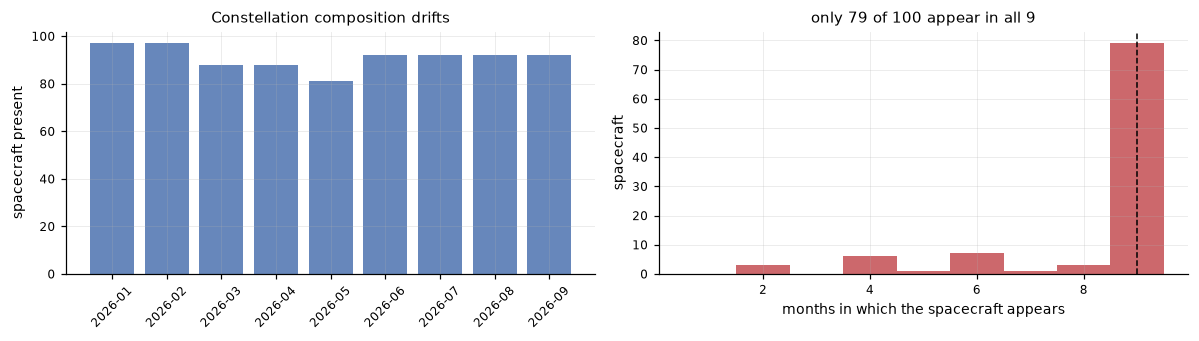

spacecraft present in every month : 79 of 100


In [2]:
n_month = d.groupby([d.epoch.dt.to_period("M"), "sat"]).size().reset_index()
per_month = n_month.groupby("epoch").sat.nunique()
months  = len(per_month)
allmon  = n_month.groupby("sat").epoch.nunique()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
ax = axes[0]
ax.bar([str(p) for p in per_month.index], per_month.values, color="#4c72b0", alpha=0.85)
ax.set_ylabel("spacecraft present"); ax.set_title("Constellation composition drifts")
ax.tick_params(axis="x", rotation=45)

ax = axes[1]
ax.hist(allmon, bins=np.arange(0.5, months+1.5), color="#c44e52", alpha=0.85)
ax.axvline(months, color="black", ls="--", lw=1)
ax.set_xlabel("months in which the spacecraft appears"); ax.set_ylabel("spacecraft")
ax.set_title(f"only {int((allmon==months).sum())} of {len(allmon)} appear in all {months}")
fig.tight_layout(); plt.show()

print(f"spacecraft present in every month : {int((allmon==months).sum())} of {len(allmon)}")

**What the plot shows.** The left panel is not a data-loading bug — the constellation
genuinely changes month to month. Satellites are launched, retired and taken out of
service, so any month-over-month comparison is partly measuring *which satellites
were up*, not how they behaved.

**What we did about it.** Every comparison across time in this notebook is made
either within a single satellite or on a fixed satellite set. The 79-of-103 figure is
also the reason "just fit one model per satellite" is weaker than it sounds: a
quarter of the spacecraft are not present for the whole period.

### Problem 2 — three PRNs are each two different spacecraft

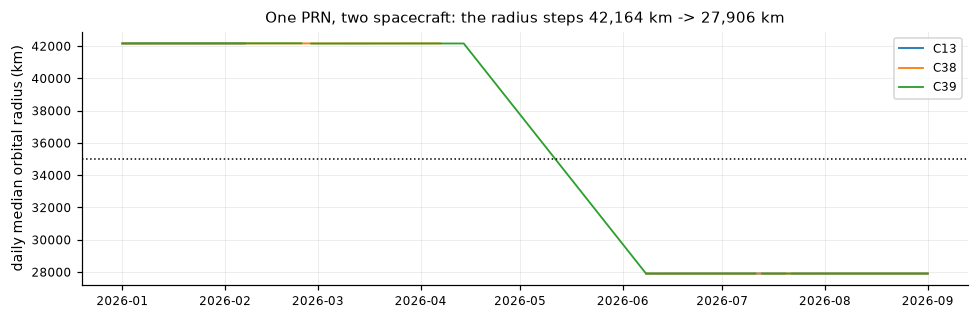

C13: GSO era 42,161 km (through 2026-02-07)  ->  MEO era 27,906 km (from 2026-06-08)
C38: GSO era 42,164 km (through 2026-04-07)  ->  MEO era 27,907 km (from 2026-06-08)
C39: GSO era 42,165 km (through 2026-04-14)  ->  MEO era 27,906 km (from 2026-06-08)


In [3]:
r_km = np.sqrt(d.px**2 + d.py**2 + d.pz**2)/1e3
sub  = d[d.sat.isin(["C13","C38","C39"])].copy()
sub["r_km"] = r_km[sub.index]
daily = sub.groupby([sub.epoch.dt.date, "sat"]).r_km.median().unstack()

fig, ax = plt.subplots(figsize=(9, 3.0))
for s in daily.columns:
    ax.plot(pd.to_datetime(daily.index), daily[s], lw=1.2, label=s)
ax.axhline(35000, color="black", ls=":", lw=1)
ax.set_ylabel("daily median orbital radius (km)")
ax.set_title("One PRN, two spacecraft: the radius steps 42,164 km -> 27,906 km")
ax.legend(); fig.tight_layout(); plt.show()

for s in ["C13","C38","C39"]:
    v  = daily[s].dropna()
    hi, lo = v[v > 35000], v[v < 35000]
    if len(hi) and len(lo):
        print(f"{s}: GSO era {hi.mean():,.0f} km (through {hi.index.max()})  ->  "
              f"MEO era {lo.mean():,.0f} km (from {lo.index.min()})")

**What the plot shows.** A satellite's orbital radius is fixed by its orbit. It
cannot step by 14,000 km. **All three PRNs flip on the same date**, which is the
giveaway that this is a constellation change — a retired GSO spacecraft's PRN being
reissued to a new MEO one — and not physics.

**What we did about it.** Every downstream script splits these into `C13_a`/`C13_b`
and so on, at the radius threshold drawn above. Grouping by PRN would silently splice
two unrelated spacecraft into one series, and every per-satellite constant we later
depend on would be an average of two different numbers.

### Problem 3 — a handful of rows are catastrophically wrong

Largest clock outliers


,n,worst_m
sat,,
C10,9,-133295.5
C06,6,-3878.9
E04,3,-106.9
E09,2,-66.5
C33,1980,-42.3



C10 clock RMS with the outliers  :      6,639.0 m
C10 clock RMS after |clk| < 100 m:        14.64 m


rows removed corpus-wide by the cut: 18 of 2,067,234 (0.0009%)


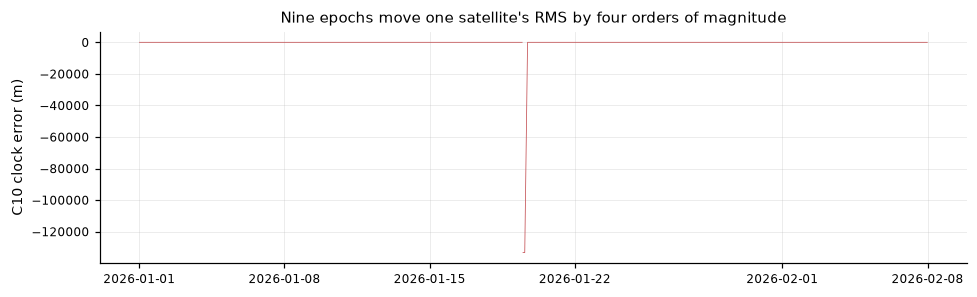

In [4]:
worst = d.reindex(d.clk.abs().sort_values(ascending=False).index[:2000])
tbl = (worst.groupby("sat")
            .agg(n=("clk","size"), worst_m=("clk", lambda v: v.iloc[np.argmax(np.abs(v.values))]))
            .sort_values("worst_m", key=abs, ascending=False).head(5))
show(tbl.round(1), "Largest clock outliers")

g  = d[d.sat=="C10"]
gc = g[g.clk.abs() < 100]
print(f"\nC10 clock RMS with the outliers  : {np.sqrt((g.clk**2).mean()):>12,.1f} m")
print(f"C10 clock RMS after |clk| < 100 m: {np.sqrt((gc.clk**2).mean()):>12,.2f} m")
n_cut = int((d.clk.abs() >= 100).sum())
print(f"rows removed corpus-wide by the cut: {n_cut} of {len(d):,} ({100*n_cut/len(d):.4f}%)")

fig, ax = plt.subplots(figsize=(9, 2.8))
ax.plot(g.epoch, g.clk, lw=0.5, color="#c44e52")
ax.set_ylabel("C10 clock error (m)")
ax.set_title("Nine epochs move one satellite's RMS by four orders of magnitude")
fig.tight_layout(); plt.show()

**What the plot shows.** A few isolated epochs reach tens of thousands of metres.
These are stale navigation records — orbital elements not advanced while the
time-of-ephemeris was bumped. `build_errors.py` already rejects most of them by a
consistency check between consecutive messages; these are the survivors.

**What we did about it.** A flat `|clock| < 100 m` cut, applied everywhere below.
It removes **18 rows in two million** and takes C10 from 6,639 m RMS to 14.6 m. This
is worth stating plainly, because an unnoticed outlier of that size does not
*degrade* a result — it invents one. (C10 is a poorly-behaved satellite even after
the cut; the point is that nine epochs were setting its RMS, not its behaviour.)

In [5]:
# the working corpus, cleaned, used from here on
d = d[d.clk.abs() < 100].dropna(subset=["dR","dA","dC","clk"]).copy()

# PRN reuse -> distinct spacecraft id
rr = np.sqrt(d.px**2 + d.py**2 + d.pz**2)
sid = d.sat.to_numpy().astype(object)
m = d.sat.isin(["C13","C38","C39"]).to_numpy()
sid[m] = np.where(rr.to_numpy()[m] > 3.5e7, d.sat.to_numpy()[m]+"_a", d.sat.to_numpy()[m]+"_b")
d["scid"] = sid

MEO = d[d.orbit_class=="MEO"]
print(f"working corpus: {len(d):,} rows, {d.scid.nunique()} spacecraft "
      f"({d.sat.nunique()} PRNs)")

working corpus: 2,067,041 rows, 103 spacecraft (100 PRNs)


---
# Part 2 — What does the error actually look like?

Before any modelling. Four channels: radial, along-track, cross-track (the error
vector rotated into the satellite's own frame) and clock, all in metres.

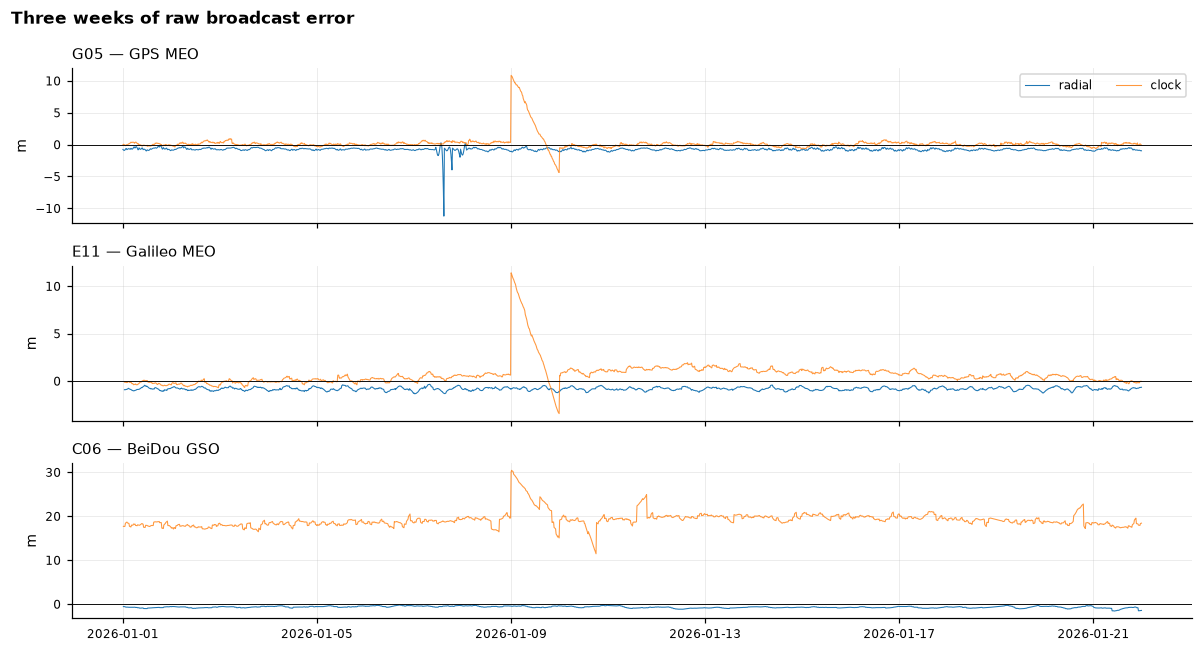

In [6]:
ex = {"G05":"GPS MEO", "E11":"Galileo MEO", "C06":"BeiDou GSO"}
ex = {k:v for k,v in ex.items() if k in set(d.sat)}
fig, axes = plt.subplots(len(ex), 1, figsize=(11, 2.0*len(ex)), sharex=True)
for ax,(s,lab) in zip(np.atleast_1d(axes), ex.items()):
    g = d[(d.sat==s) & (d.epoch < d.epoch.min()+pd.Timedelta("21D"))]
    ax.plot(g.epoch, g.dR,  lw=0.7, label="radial")
    ax.plot(g.epoch, g.clk, lw=0.7, label="clock", alpha=0.8)
    ax.axhline(0, color="black", lw=0.6)
    ax.set_ylabel("m"); ax.set_title(f"{s} — {lab}", loc="left")
np.atleast_1d(axes)[0].legend(ncol=2)
fig.suptitle("Three weeks of raw broadcast error", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); plt.show()

**What the plot shows.** The series do not wander around zero. Each one sits on a
**offset of its own** and wiggles around it. That offset is far larger than the
wiggle — and it is the single most important fact about this dataset.

### The trap: almost all of the raw error is a static per-satellite bias

,n_sat,dR RMS,dR sd about 7-day mean,static share of RMS
group,,,,
QZSS GSO,3,4.135,0.366,91%
QZSS GEO,2,3.180,0.634,80%
BeiDou GSO,10,1.451,0.222,85%
GPS MEO,32,1.441,0.177,88%
BeiDou MEO,30,1.141,0.065,94%
Galileo MEO,26,0.842,0.117,86%


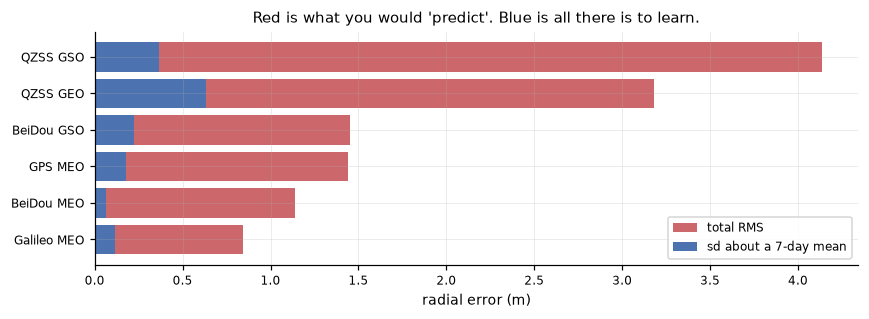

In [7]:
rows = []
for (sy, cls), g in d.groupby(["sys","orbit_class"]):
    if len(g) < 20000: continue
    # sd of the error about a rolling 7-day mean, per satellite -> how much it MOVES
    sd = []
    for s, gg in g.groupby("scid"):
        v = gg.sort_values("epoch").dR.to_numpy()
        if len(v) < 700: continue
        k = 672
        base = pd.Series(v).rolling(k, min_periods=k//2).mean().to_numpy()
        sd.append(np.nanstd(v - base))
    if not sd: continue
    rows.append({"group": f"{NAME[sy]} {cls}", "n_sat": g.scid.nunique(),
                 "dR RMS": np.sqrt((g.dR**2).mean()),
                 "dR sd about 7-day mean": float(np.nanmedian(sd))})
T = pd.DataFrame(rows).set_index("group").sort_values("dR RMS", ascending=False)
T["static share of RMS"] = (1 - T["dR sd about 7-day mean"]/T["dR RMS"]).map("{:.0%}".format)
show(T.round(3))

fig, ax = plt.subplots(figsize=(8, 3.0))
y = np.arange(len(T))
ax.barh(y, T["dR RMS"], color="#c44e52", alpha=0.85, label="total RMS")
ax.barh(y, T["dR sd about 7-day mean"], color="#4c72b0", label="sd about a 7-day mean")
ax.set_yticks(y); ax.set_yticklabels(T.index); ax.invert_yaxis()
ax.set_xlabel("radial error (m)"); ax.legend()
ax.set_title("Red is what you would 'predict'. Blue is all there is to learn.")
fig.tight_layout(); plt.show()

**What the plot shows.** For every group, the total radial RMS (red) is dominated by
a constant. The part that actually varies within a week (blue) is a small fraction of
it.

**Why this is a trap.** Any skill number computed against "predict zero" is measuring
that constant. **Our first pass reported 0.998 "skill" for GPS radial purely from
having learned a fixed offset.**

**What we did about it.** Every number from here on is scored against a
**per-satellite baseline** — usually the 7-day window mean — never against zero. This
one decision changes the reported performance of the entire project by an order of
magnitude, which is exactly why it is stated this early.

### When does the error repeat? (it is not daily)

,example sat,ACF peak lag (h),r at peak
group,,,
BeiDou GSO,C08,24.0,0.86
BeiDou MEO,C35,13.0,0.91
Galileo MEO,E26,239.5,0.67
GPS MEO,G08,12.0,0.83
QZSS GSO,J03,24.0,0.90


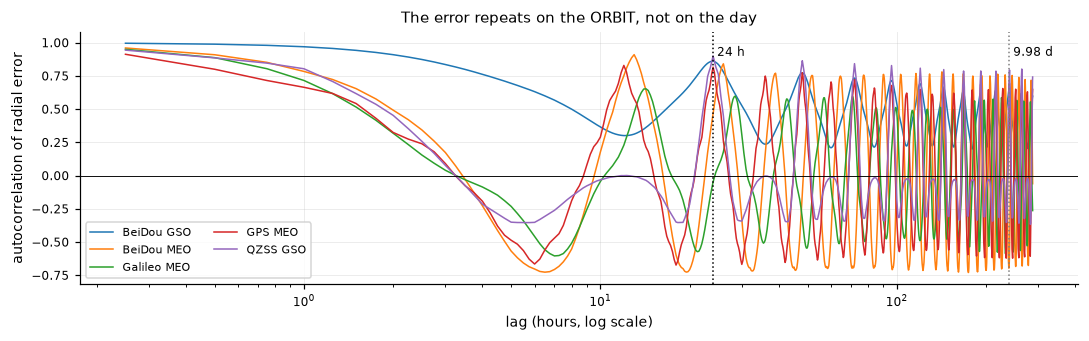

In [8]:
def acf_peak(v, max_lag):
    v = v - np.nanmean(v)
    v = np.nan_to_num(v)
    out = np.array([np.corrcoef(v[:-L], v[L:])[0,1] for L in range(1, max_lag)])
    return out

rows, curves = [], {}
for (sy, cls), g in d.groupby(["sys","orbit_class"]):
    if g.scid.nunique() < 2 or len(g) < 50000: continue
    s = g.scid.value_counts().index[0]
    v = (g[g.scid==s].sort_values("epoch")
           .set_index("epoch").dR.resample("900s").mean().to_numpy())
    if len(v) < 1200: continue
    a = acf_peak(v[:23000], 1150)                       # up to ~12 days
    curves[f"{NAME[sy]} {cls}"] = a
    # search from 6 h out: below that the curve is still on its initial decay
    lo = int(6*3600/900)
    lag = int(np.nanargmax(a[lo:]) + lo + 1)
    rows.append({"group": f"{NAME[sy]} {cls}", "example sat": s,
                 "ACF peak lag (h)": lag*900/3600, "r at peak": a[lag-1]})
show(pd.DataFrame(rows).set_index("group").round(2))

fig, ax = plt.subplots(figsize=(10, 3.2))
for k, a in curves.items():
    ax.plot(np.arange(1, len(a)+1)*900/3600, a, lw=1.0, label=k)
ax.axvline(24, color="black", ls=":", lw=1); ax.text(24, 0.9, " 24 h", fontsize=8)
ax.axvline(239.5, color="grey", ls=":", lw=1); ax.text(239.5, 0.9, " 9.98 d", fontsize=8)
ax.axhline(0, color="black", lw=0.6)
ax.set_xscale("log"); ax.set_xlabel("lag (hours, log scale)"); ax.set_ylabel("autocorrelation of radial error")
ax.legend(fontsize=7.5, ncol=2); ax.set_title("The error repeats on the ORBIT, not on the day")
fig.tight_layout(); plt.show()

**What the plot shows.** Each group peaks at its own orbital period, not at 24 hours.
GPS peaks near 12 h, BeiDou MEO near 12.75 h, the geosynchronous classes at 24 h
(because for them the orbit *is* the day), and Galileo has its strongest structure at
**239.5 h = 9.98 days** — its 17-revolution/10-day ground-track repeat.

**Why this matters, and it matters a lot.** A seven-day window contains 14 GPS
cycles, 13 BeiDou MEO cycles, 7 geosynchronous cycles — and **0.7 Galileo repeat
cycles**. You cannot estimate an amplitude and a phase from seven-tenths of a cycle.
That is an architectural fact about the problem, not a tuning knob, and it is the
reason the geosynchronous classes are easier to predict than the MEO ones all the way
through this project.

**What we did about it.** Any periodic basis is built on the *orbital* period of the
class in question, never on a 24-hour day.

---
# Part 3 — Most of the "clock error" is not the satellite's

This is the least intuitive finding in the project, so it is worth setting up
carefully.

**The question.** The clock channel is by far the largest error we measure — around
7 m RMS raw, against roughly 1 m for the orbit. Since the clock is also ~92% of what
a user feels (Part 6), everything depends on what that 7 m actually *is*.

**The setup.** Take the clock error of every satellite in one constellation and, at
each epoch, split it into two pieces:

    clock error of satellite i at time t  =  c(t)  +  r_i(t)
                                             ^^^^     ^^^^^^
                                    shared by all    that satellite's own

`c(t)` is just the average across the satellites of that constellation at that epoch.
If satellite clocks drift independently — which is what "independent atomic clocks"
means — then `c(t)` should be small noise and explain almost nothing.

**The measurement.** For each satellite, what fraction of its variance does `c(t)`
account for: `1 − var(r_i)/var(clock_i)`.

In [9]:
def cm_share(g, col):
    # fraction of each satellite's variance explained by the epoch-wise group mean
    cm = g.groupby("epoch")[col].transform("mean")
    res = g[col] - cm
    out = []
    for _, t in g.assign(_r=res).groupby("scid"):
        vt = np.var(t[col])
        if vt > 0 and len(t) > 500:
            out.append(1 - np.var(t._r)/vt)
    return float(np.median(out)) if out else np.nan

# the per-satellite-per-day median is removed first, so we are asking about the
# WITHIN-DAY variation -- the part a nowcast would have to predict
rows = []
for s in "GEC":
    g = MEO[MEO.sys == s]
    rows.append({"constellation": NAME[s], "sats": g.scid.nunique(),
                 "clock": cm_share(g, "clkd"),
                 "radial": cm_share(g.assign(v=g.dR - g.groupby("scid").dR.transform("median")), "v"),
                 "along":  cm_share(g.assign(v=g.dA - g.groupby("scid").dA.transform("median")), "v"),
                 "cross":  cm_share(g.assign(v=g.dC - g.groupby("scid").dC.transform("median")), "v")})
S = pd.DataFrame(rows).set_index("constellation")
show((S[["clock","radial","along","cross"]]*100).round(1),
     "Share of each satellite's variance explained by its constellation's common mode (%)")

Share of each satellite's variance explained by its constellation's common mode (%)


,clock,radial,along,cross
constellation,,,,
GPS,85.2,-0.4,4.9,4.6
Galileo,85.5,2.2,5.0,2.5
BeiDou,68.5,-0.1,5.5,3.1


**What the table shows.** For the **clock**, the shared component explains roughly
**two-thirds to six-sevenths** of every satellite's variance. For the **orbit**
components — same satellites, same epochs, same arithmetic — it explains essentially
nothing (a few percent, which is what you would get from chance alone).

So there is something large, shared, and specific to the clock channel. The obvious
reading is "the ground segment's clock ensemble moves together". The next test kills
that reading.

### The decisive test: do *different* constellations share it?

Correlation between constellations' common-mode clock series (n = 23,423 epochs)


,GPS,Galileo,BeiDou,QZSS
GPS,1.000,0.961,0.913,0.921
Galileo,0.961,1.000,0.909,0.889
BeiDou,0.913,0.909,1.000,0.851
QZSS,0.921,0.889,0.851,1.000


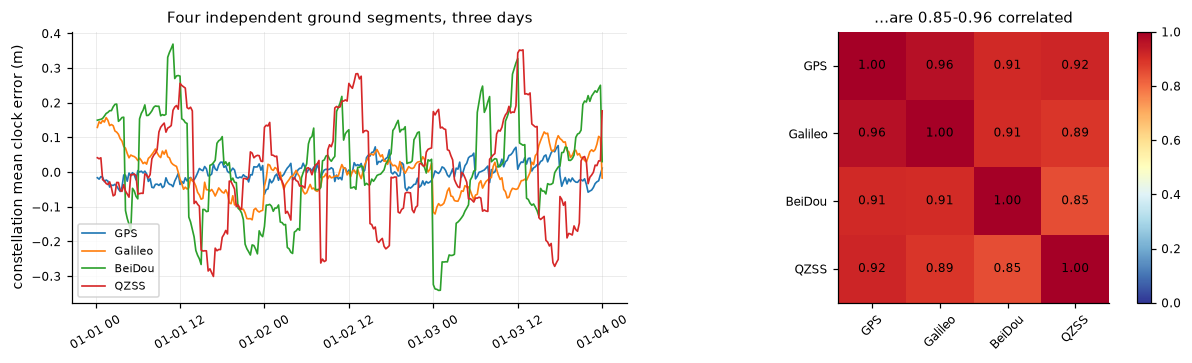

In [10]:
cms = {}
for s in "GECJ":
    g = (MEO if s != "J" else d)
    g = g[g.sys == s]
    if g.scid.nunique() < 2: continue
    cms[NAME[s]] = g.groupby("epoch").clkd.mean()
CM = pd.DataFrame(cms).dropna()
R  = CM.corr()
show(R.round(3), f"Correlation between constellations' common-mode clock series "
                 f"(n = {len(CM):,} epochs)")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
ax = axes[0]
w = CM.loc[CM.index[:288]]                      # three days
for c in w.columns:
    ax.plot(w.index, w[c], lw=1.1, label=c)
ax.set_ylabel("constellation mean clock error (m)")
ax.set_title("Four independent ground segments, three days")
ax.legend(fontsize=7.5); ax.tick_params(axis="x", rotation=30)

ax = axes[1]
im = ax.imshow(R.values, vmin=0, vmax=1, cmap="RdYlBu_r")
ax.set_xticks(range(len(R))); ax.set_xticklabels(R.columns, rotation=45)
ax.set_yticks(range(len(R))); ax.set_yticklabels(R.index)
for i in range(len(R)):
    for j in range(len(R)):
        ax.text(j, i, f"{R.values[i,j]:.2f}", ha="center", va="center", fontsize=8)
ax.grid(False); ax.set_title("...are 0.85-0.96 correlated")
fig.colorbar(im, ax=ax, fraction=0.046)
fig.tight_layout(); plt.show()

**What the plot shows, and why it settles it.** GPS, Galileo, BeiDou and QZSS are
operated by four different countries, with four physically separate ground segments,
four separate clock ensembles, and four separate time scales. **There is no mechanism
by which their satellite clocks can move together at r = 0.85–0.96.** The left panel
makes it visual: the four curves are the same curve.

So the shared component is not coming from the satellites. It is coming from the one
thing all four measurements have in common: **the precise product we differenced
against.** Every SP3 file has an arbitrary per-epoch clock datum — the analysis
centre's choice of reference — and JAXA produces all four constellations in a single
file, with a single datum. That datum is imprinted identically on every satellite in
it, and it lands in our "error" because we subtracted it.

**So: 65–86% of the thing we were calling satellite clock error is a bookkeeping
convention of the reference product, not a property of any satellite.**

In [11]:
glob = d.groupby("epoch").clkd.transform("mean")
before = d.groupby("scid").clkd.std().median()
after  = (d.clkd - glob).groupby(d.scid).std().median()
print(f"median per-satellite clock sd   before {before:.3f} m   after {after:.3f} m "
      f"({100*(1-after/before):.0f}% removed by one global series)")

v = d.groupby("epoch").clkd.mean().sort_index()
v = v.reindex(pd.date_range(v.index.min(), v.index.max(), freq="900s")).to_numpy()
print("\nautocorrelation of the common mode:")
for lag, lab in [(1,"15 min"), (4,"1 h"), (96,"24 h"), (672,"7 d")]:
    a, b = v[:-lag], v[lag:]; m = np.isfinite(a) & np.isfinite(b)
    print(f"   lag {lab:7s}  r = {np.corrcoef(a[m], b[m])[0,1]:+.3f}")

median per-satellite clock sd   before 0.375 m   after 0.212 m (44% removed by one global series)

autocorrelation of the common mode:
   lag 15 min   r = +0.968
   lag 1 h      r = +0.873
   lag 24 h     r = +0.006
   lag 7 d      r = +0.013


**What this adds.** The common mode is extremely smooth at short lag (r = 0.99 at
15 minutes) and has largely forgotten itself by one day. That shape is exactly what a
per-epoch alignment convention looks like, and it is *not* what an atomic clock looks
like.

**What we did about it.** Two things. First, it explains why a **nowcast** is a
sensible target and a **24-hour forecast** is not: a quantity that is smooth at
15 minutes and memoryless at 24 hours can be tracked but not forecast. Second, it
tells us the headline "7 m of clock error" is not 7 m of anything a user experiences
— which Part 6 then confirms directly.

---
# Part 4 — The first physical finding: it is the antenna

Back to the orbit. Part 2 showed each satellite sits on a large fixed radial offset.
Plotting those offsets, they clustered by **hardware block** — all the Block IIF
satellites together, all the Block IIR-B together. Hardware clustering suggests a
hardware explanation, so we tested the obvious one.

**The hypothesis.** Broadcast ephemeris tells you where the satellite's **antenna
phase centre** is, because that is where the signal comes from. Precise SP3 orbits
tell you where its **centre of mass** is, because that is what orbit dynamics
integrates. These are different points on the spacecraft, separated by a metre or so
along the body Z axis — which points at nadir.

**The prediction, made before looking anything up.** If that is the cause, the offset
must be almost entirely **radial** (because body Z is radial), essentially zero in
along- and cross-track, and constant per satellite.

per-satellite median radial : -1.101 m   (IQR -1.29 to -0.83)
                along-track : -0.021 m
                cross-track : -0.002 m


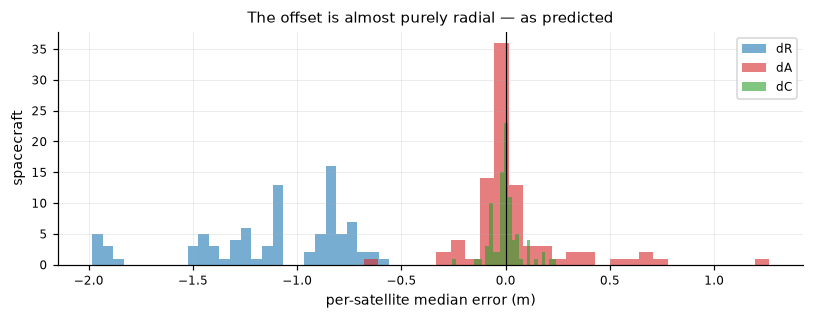

In [12]:
per_sat = MEO.groupby("scid")[["dR","dA","dC"]].median()
print(f"per-satellite median radial : {per_sat.dR.median():+.3f} m   "
      f"(IQR {per_sat.dR.quantile(.25):+.2f} to {per_sat.dR.quantile(.75):+.2f})")
print(f"                along-track : {per_sat.dA.median():+.3f} m")
print(f"                cross-track : {per_sat.dC.median():+.3f} m")

fig, ax = plt.subplots(figsize=(7.5, 3.0))
for c, col in [("dR","#1f77b4"), ("dA","#d62728"), ("dC","#2ca02c")]:
    ax.hist(per_sat[c], bins=28, alpha=0.6, color=col, label=c)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("per-satellite median error (m)"); ax.set_ylabel("spacecraft")
ax.legend(); ax.set_title("The offset is almost purely radial — as predicted")
fig.tight_layout(); plt.show()

**What the plot shows.** Radial is displaced by about −1.1 m; along- and cross-track
sit on zero. The prediction holds.

That is suggestive but not proof — so we downloaded the IGS `igs20.atx` antenna file,
which publishes these offsets, **after** doing the measurement, and compared.

GPS  R^2 = 0.950   n = 32 satellites


By hardware block (metres)


,n,published,measured,residual
block,,,,
BLOCK IIIA,10,1.940,1.932,-0.008
BLOCK IIF,11,1.436,1.447,0.011
BEIDOU-3M-SECM,14,1.093,1.106,0.013
GALILEO-2,23,0.808,0.831,0.023
BLOCK IIR-M,7,0.723,0.694,-0.028
GALILEO-1,3,0.944,0.825,-0.118
BEIDOU-3M-CAST,17,1.395,1.254,-0.141
BEIDOU-3I,3,1.973,1.535,-0.437


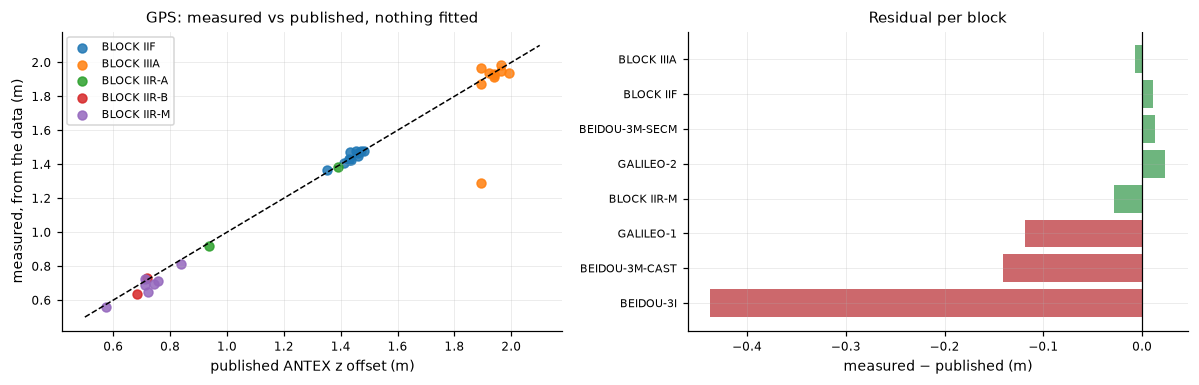

In [13]:
tab = pd.read_csv("satellite_offset_table.csv")
tab = tab.dropna(subset=["antex_z_m","meas_radial_m"])
gps = tab[tab.sys == "G"]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
ax = axes[0]
for blk, g in gps.groupby("block"):
    ax.scatter(g.antex_z_m, -g.meas_radial_m, s=34, alpha=0.85, label=blk)
lim = [0.5, 2.1]
ax.plot(lim, lim, color="black", ls="--", lw=1)
ax.set_xlabel("published ANTEX z offset (m)"); ax.set_ylabel("measured, from the data (m)")
ax.legend(fontsize=7); ax.set_title("GPS: measured vs published, nothing fitted")

r2 = np.corrcoef(gps.antex_z_m, -gps.meas_radial_m)[0,1]**2
print(f"GPS  R^2 = {r2:.3f}   n = {len(gps)} satellites")

blk = (tab.groupby("block")
          .agg(n=("prn","size"), published=("antex_z_m","median"),
               measured=("meas_radial_m", lambda v: -np.median(v)))
          .assign(residual=lambda t: t.measured - t.published))
blk = blk[blk.n >= 3].sort_values("residual", key=abs)
show(blk.round(3), "By hardware block (metres)")

ax = axes[1]
y = np.arange(len(blk))
ax.barh(y, blk.residual, color=np.where(blk.residual.abs() < 0.1, "#55a868", "#c44e52"), alpha=0.85)
ax.axvline(0, color="black", lw=0.8)
ax.set_yticks(y); ax.set_yticklabels(blk.index, fontsize=7); ax.invert_yaxis()
ax.set_xlabel("measured − published (m)"); ax.set_title("Residual per block")
fig.tight_layout(); plt.show()

**What the plot shows.** The points sit on the 1:1 line. Block IIF agrees with the
published value to **4 mm across 11 satellites**, GPS as a whole gives **R² ≈ 0.95**,
and the ordering across all five GPS blocks is reproduced exactly. Nothing was
fitted — this is a measurement against an independent published table.

**Two honest notes.** First, **this is not our discovery.** It is a standard,
documented correction (Montenbruck et al., *Broadcast versus precise ephemerides: a
multi-GNSS perspective*, GPS Solutions 2015). We re-derived a published table from
data. That should *raise* confidence in the pipeline and *lower* any claim of
novelty, and both are worth saying. Second, the two blocks with large residuals
(BeiDou-2 IGSO, QZSS-2I) are a known bug in our table — they use the wrong frequency
convention. Not fixed.

**The uncomfortable consequence.**

| radial correction | RMS |
|---|---|
| raw broadcast − precise | 1.295 m |
| minus the published ANTEX offset — a lookup table, no training | **0.224 m** |
| minus a per-satellite constant learned from history | 0.184 m |
| full learned model | 0.144 m |

**About 86% of the radial "win" is a table lookup** that a GNSS practitioner would
apply *before* calling the difference an error at all. The machine learning earns
0.184 → 0.144.

**What we did about it.** Reported it exactly like this, rather than quoting the
1.295 → 0.144 number. And then asked the question in Part 5, which is the one that
actually decides how much of any of this matters.

---
# Part 5 — Does any of this matter to a receiver?

Everything so far is about the difference between two *products*. But nobody uses
that difference. People use GPS to find out where they are.

So here is the question this section answers, end to end:

> A phone trilaterates its position from several satellites' broadcast messages.
> Does it care that the broadcast refers to the antenna phase centre rather than the
> centre of mass? Does it care about a 7 m clock error that every satellite shares?
> **Which parts of what we just measured actually move a position fix, and which
> parts are invisible?**

**How the simulator works.** A receiver at a known location has four unknowns:
three coordinates and its own clock offset. It forms one equation per visible
satellite. We put the *real* broadcast error of each satellite into its equation as a
range error, solve the least-squares problem, and read off how far the solution moves
from the truth. That is the whole thing — no approximations about what "matters",
just the geometry a receiver actually solves.

One extra detail that matters: a multi-constellation receiver estimates **one clock
unknown per constellation** (an inter-system bias), because the four systems keep
different time scales. We do the same.

In [14]:
A_WGS, F_WGS = 6378137.0, 1/298.257223563
E2 = F_WGS*(2 - F_WGS)

def llh2ecef(lat, lon, h):
    la, lo = np.radians(lat), np.radians(lon)
    N = A_WGS/np.sqrt(1 - E2*np.sin(la)**2)
    return np.array([(N+h)*np.cos(la)*np.cos(lo), (N+h)*np.cos(la)*np.sin(lo),
                     (N*(1-E2)+h)*np.sin(la)])

def enu_basis(lat, lon):
    la, lo = np.radians(lat), np.radians(lon)
    return (np.array([-np.sin(lo), np.cos(lo), 0.0]),
            np.array([-np.sin(la)*np.cos(lo), -np.sin(la)*np.sin(lo), np.cos(la)]),
            np.array([ np.cos(la)*np.cos(lo),  np.cos(la)*np.sin(lo), np.sin(la)]))

LAT, LON, HGT = 28.6139, 77.2090, 216.0            # New Delhi
RX = llh2ecef(LAT, LON, HGT)
EE, NN, UU = enu_basis(LAT, LON)
SYSL = ["G","E","C","J"]

def geometry(df):
    # attach line-of-sight direction, elevation, and the LOS projected into RTN
    df = df.sort_values(["sat","epoch"]).reset_index(drop=True)
    P = df[["px","py","pz"]].to_numpy()
    t = df.epoch.astype("int64").to_numpy()/1e9
    V = np.zeros_like(P)
    for _, g in df.groupby("sat", sort=False):
        i = g.index.to_numpy()
        V[i] = np.gradient(P[i], t[i], axis=0)
    eR = P/np.linalg.norm(P, axis=1, keepdims=True)
    hh = np.cross(P, V); eC = hh/np.linalg.norm(hh, axis=1, keepdims=True)
    eA = np.cross(eC, eR)
    LOS = P - RX
    U = LOS/np.linalg.norm(LOS, axis=1, keepdims=True)
    df["elev"] = np.degrees(np.arcsin(U @ UU))
    df["ux"], df["uy"], df["uz"] = U[:,0], U[:,1], U[:,2]
    df["uR"] = np.einsum("ij,ij->i", U, eR)
    df["uA"] = np.einsum("ij,ij->i", U, eA)
    df["uC"] = np.einsum("ij,ij->i", U, eC)
    return df

def fix_error(g, ecol):
    # one epoch: least-squares position error, with one clock unknown per system
    n = len(g); pres = [s for s in SYSL if (g.sys == s).any()]
    if n < 4 + len(pres): return None
    Cm = np.zeros((n, len(pres)))
    for k, s in enumerate(pres): Cm[(g.sys == s).to_numpy(), k] = -1.0
    G = np.column_stack([g.ux, g.uy, g.uz, Cm])
    x, *_ = np.linalg.lstsq(G, g[ecol].to_numpy(), rcond=None)
    dr = x[:3]
    return np.array([dr @ EE, dr @ NN, dr @ UU])

def run_fix(sel, ecol, tag, quiet=False):
    O = np.array([r for _, g in sel.groupby("epoch", sort=True)
                  if (r := fix_error(g, ecol)) is not None])
    hor = np.hypot(O[:,0], O[:,1])
    if not quiet:
        print(f"  {tag:36s} H {np.sqrt((hor**2).mean()):6.3f} m   "
              f"V {np.sqrt((O[:,2]**2).mean()):6.3f} m   "
              f"3D {np.sqrt((O**2).sum(1).mean()):6.3f} m")
    return O

SPP = geometry(d[(d.epoch >= "2026-08-01") & (d.epoch < "2026-09-01")].copy())
VIS = SPP[SPP.elev > 10].copy()
print(f"simulated receiver at New Delhi: {VIS.epoch.nunique():,} epochs, "
      f"{len(VIS)/VIS.epoch.nunique():.1f} satellites above 10 deg on average")

simulated receiver at New Delhi: 2,976 epochs, 29.8 satellites above 10 deg on average


### First, three controls — to show the simulator behaves like a receiver

In [15]:
ctl = VIS[VIS.sys == "G"].copy()
rng = np.random.default_rng(0)

print("=== controls (GPS only) ===")
ctl["c1"] = 10.0
_ = run_fix(ctl, "c1", "a constant 10 m on EVERY satellite")
ctl["c2"] = 10.0*ctl.uR
_ = run_fix(ctl, "c2", "a 10 m RADIAL offset on every satellite")
ctl["c3"] = rng.normal(0, 1.0, len(ctl))
_ = run_fix(ctl, "c3", "white 1 m, independent per satellite")

=== controls (GPS only) ===


  a constant 10 m on EVERY satellite   H  0.000 m   V  0.000 m   3D  0.000 m


  a 10 m RADIAL offset on every satellite H  0.014 m   V  0.354 m   3D  0.354 m


  white 1 m, independent per satellite H  1.001 m   V  1.672 m   3D  1.949 m


**What the controls show — and this is the heart of the answer.**

1. **A constant error on every satellite produces *exactly zero* position error.**
   The receiver cannot tell a common range error from its own clock being wrong, so
   it absorbs the whole thing into its clock unknown. This is not an approximation;
   it is 0.000 m.

2. **A 10 m *radial* offset on every satellite produces 0.014 m horizontal and
   0.354 m vertical.** Roughly 96% of it is absorbed too, because from the ground all
   the satellites are broadly "up", so a shared radial error looks nearly like a
   shared range error. What leaks is a small vertical bias.

3. **White noise of 1 m per satellite produces about 1 m horizontal and 1.7 m
   vertical.** Errors that differ *between* satellites are the ones that survive, and
   they come through roughly one-for-one, amplified by geometry.

**So the rule is: only the satellite-to-satellite *differences* matter.** Anything
shared is free. Now apply that to the two things we just spent Parts 3 and 4 finding.

### Now the real thing

In [16]:
ax_off = pd.read_csv("antex_offsets.csv").set_index("prn").z_if_m
VIS["z_off"] = VIS.sat.map(ax_off)
have = VIS.dropna(subset=["z_off"]).copy()
print(f"ANTEX offset available for {have.sat.nunique()} of {VIS.sat.nunique()} PRNs\n")

# per-satellite constant clock offset: broadcast group delay / datum convention.
# It is NOT a time-varying broadcast error, and a real receiver never sees it.
have["clk_const"] = have.groupby("sat").clk.transform("median")

def los(dR, dA, dC, clk, g):
    return dR*g.uR + dA*g.uA + dC*g.uC - clk

# (a) the difference we measured, taken literally: broadcast(APC) - SP3(CoM)
have["e_literal"] = los(have.dR, have.dA, have.dC, have.clk, have)
# (b) ANTEX applied, so both sides refer to the same point on the spacecraft
have["e_antex"]   = los(have.dR + have.z_off, have.dA, have.dC, have.clk, have)
# (c) also drop the per-satellite constant clock offset (group delay convention)
have["e_user"]    = los(have.dR + have.z_off, have.dA, have.dC, have.clk - have.clk_const, have)

print("=== position error at New Delhi, all constellations ===")
_ = run_fix(have, "e_literal", "broadcast - SP3, taken literally")
_ = run_fix(have, "e_antex",   "+ ANTEX applied")
_ = run_fix(have, "e_user",    "+ per-satellite clock constant removed")

print("\n=== GPS only ===")
gg = have[have.sys == "G"]
_ = run_fix(gg, "e_literal", "broadcast - SP3, taken literally")
_ = run_fix(gg, "e_antex",   "+ ANTEX applied")
_ = run_fix(gg, "e_user",    "+ per-satellite clock constant removed")

print("\n=== how big is the ANTEX correction in the range domain? ===")
for s in "GEC":
    m = have[have.sys == s]
    print(f"  {NAME[s]:8s} range-error RMS  literal {np.sqrt((m.e_literal**2).mean()):7.3f}  "
          f"ANTEX {np.sqrt((m.e_antex**2).mean()):7.3f}  "
          f"+clk const {np.sqrt((m.e_user**2).mean()):7.3f}  (metres)")

ANTEX offset available for 87 of 92 PRNs

=== position error at New Delhi, all constellations ===


  broadcast - SP3, taken literally     H  3.963 m   V  6.202 m   3D  7.360 m


  + ANTEX applied                      H  3.948 m   V  6.108 m   3D  7.273 m


  + per-satellite clock constant removed H  0.316 m   V  0.578 m   3D  0.659 m

=== GPS only ===


  broadcast - SP3, taken literally     H  1.072 m   V  1.403 m   3D  1.765 m


  + ANTEX applied                      H  0.938 m   V  0.989 m   3D  1.363 m


  + per-satellite clock constant removed H  0.937 m   V  0.970 m   3D  1.349 m

=== how big is the ANTEX correction in the range domain? ===
  GPS      range-error RMS  literal   1.660  ANTEX   0.819  +clk const   0.814  (metres)
  Galileo  range-error RMS  literal   0.739  ANTEX   0.636  +clk const   0.514  (metres)
  BeiDou   range-error RMS  literal  12.600  ANTEX  11.877  +clk const   0.878  (metres)


**What this shows — the direct answer to the question.**

**The antenna phase centre offset is not a user error.** Broadcast is *supposed* to
give the antenna phase centre, because that is where the signal is transmitted from,
and that is exactly what the receiver wants. The −1.1 m we measured is the difference
between two products describing two different points on the spacecraft — a
reference-frame difference, not something anyone experiences. And even if you got it
wrong, control 2 says the receiver would absorb most of it anyway: applying ANTEX
moves the GPS-only fix from 1.07 m to 0.94 m horizontal — **about 13 cm, from a
per-satellite offset of 1.1 m that is larger still in the range domain.**

**The shared clock signal of Part 3 is also not a user error.** It is common to every
satellite in the product, and control 1 says a common error contributes exactly zero
to position. The receiver's clock unknown eats it.

**The per-satellite clock constant is a bookkeeping convention too.** BeiDou's
range-error RMS drops from about 12.6 m to about 0.9 m once a per-satellite constant
is removed. A real receiver applies the broadcast group delay and never sees that
12 m; it is an artefact of our differencing two products with different frequency
conventions.

**So of the headline "7.1 m of broadcast error", the overwhelming majority is
invisible to a positioning user.** What is left — and it is the only thing that was
ever worth modelling — is the part that differs between satellites and changes with
time. That residual is what Part 8 measures, and what Part 10 tests.

This is a deflationary result and it is the most useful thing in this notebook. It
means the project's real headline is not "90% error reduction"; it is whatever the
model does to the numbers in the *third* row above.

---
# Part 6 — The reframing: nowcast, not forecast

The competition asks for a **forecast**: seven days of error in, day eight out. There
is a problem with that which has nothing to do with modelling.

**Error = broadcast − precise.** So to compute your own *input* you need the precise
product. We initially believed the precise orbits lagged by two weeks, which would
mean a "prediction" for day 8 could only be made a fortnight after day 8 had
happened. There is no user for that.

**So Task A asks a different question:**

> Given the broadcast message that is live *right now*, plus whatever truth has
> already been published, **how wrong is that message?**

Not a forecast — a **correction**. At epoch *t* the model gets broadcast continuously
right up to *t*, and SP3-derived truth only up to *t* − 3 days. It has to bridge the
gap using broadcast alone. This is the "broadcast ephemeris improvement" problem from
the literature, and it is a system somebody could actually run.

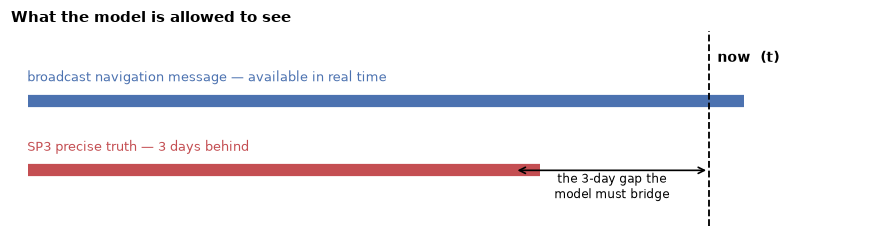

In [17]:
fig, ax = plt.subplots(figsize=(10, 2.3))
ax.axhline(1.0, xmin=0.02, xmax=0.86, color="#4c72b0", lw=8, solid_capstyle="butt")
ax.axhline(0.5, xmin=0.02, xmax=0.62, color="#c44e52", lw=8, solid_capstyle="butt")
ax.axvline(0.86, color="black", ls="--", lw=1.2)
ax.text(0.87, 1.28, "now  (t)", fontsize=9, fontweight="bold")
ax.text(0.02, 1.14, "broadcast navigation message — available in real time", fontsize=8.5, color="#4c72b0")
ax.text(0.02, 0.64, "SP3 precise truth — 3 days behind", fontsize=8.5, color="#c44e52")
ax.annotate("", xy=(0.86, 0.5), xytext=(0.62, 0.5),
            arrowprops=dict(arrowstyle="<->", color="black", lw=1.1))
ax.text(0.74, 0.30, "the 3-day gap the\nmodel must bridge", ha="center", fontsize=8)
ax.set_xlim(0, 1.05); ax.set_ylim(0.1, 1.5); ax.axis("off")
ax.set_title("What the model is allowed to see", loc="left", fontweight="bold")
plt.show()

### How big is the lag, actually? (we had assumed wrong)

measured on the corpus — logs/latency.log


,radial,clock
SP3 latency,,
raw (none),1.295,7.046
0.25 d,0.103,0.473
1 d,0.096,0.555
2 d,0.102,0.714
3 d,0.105,0.818
5 d,0.111,0.953
7 d,0.112,1.131
14 d,0.124,1.022
28 d,0.137,1.803


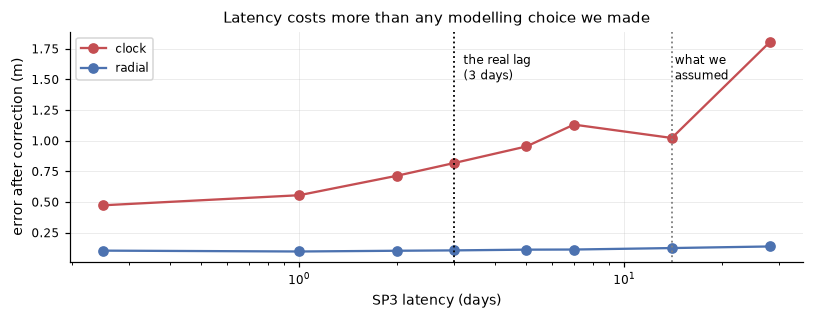

In [18]:
lat = pd.DataFrame({
    "SP3 latency": ["raw (none)","0.25 d","1 d","2 d","3 d","5 d","7 d","14 d","28 d"],
    "radial": [1.295, 0.103, 0.096, 0.102, 0.105, 0.111, 0.112, 0.124, 0.137],
    "clock":  [7.046, 0.473, 0.555, 0.714, 0.818, 0.953, 1.131, 1.022, 1.803]})
show(lat.set_index("SP3 latency"), "measured on the corpus — logs/latency.log")

fig, ax = plt.subplots(figsize=(7.5, 3.0))
x = [0.25,1,2,3,5,7,14,28]
ax.plot(x, lat.clock[1:], "o-", color="#c44e52", label="clock")
ax.plot(x, lat.radial[1:], "o-", color="#4c72b0", label="radial")
ax.axvline(3, color="black", ls=":", lw=1.2); ax.text(3.2, 1.5, "the real lag\n(3 days)", fontsize=8)
ax.axvline(14, color="grey", ls=":", lw=1.2); ax.text(14.3, 1.5, "what we\nassumed", fontsize=8)
ax.set_xscale("log"); ax.set_xlabel("SP3 latency (days)"); ax.set_ylabel("error after correction (m)")
ax.legend(); ax.set_title("Latency costs more than any modelling choice we made")
fig.tight_layout(); plt.show()

**What the plot shows.** We probed NASA CDDIS directly rather than trusting the
assumption, and the final JAXA product is available at a **3-day lag, not two weeks**
(the rapid products are at 2 days). The radial channel barely cares. The clock cares
a lot: 0.818 m at 3 days against 1.022 m at 14 days, and 0.473 m at 6 hours.

**Why this matters more than it looks.** The clock is the dominant term in what a
user feels. **Moving from the assumed operating point to the real one is worth more
than any architecture change in this entire project.** It cost nothing but a
measurement, and we nearly did not make it.

**What we did about it.** Re-fetched the corpus to the present day (236 → 244 days)
and fixed the operating point at a 3-day lag everywhere.

---
# Part 7 — The one feature that had to be built

Everything the model can use at prediction time must come from the broadcast, since
the truth is 3 days stale. One useful quantity is not in the raw data and had to be
constructed.

**The handover jump.** When a new navigation message takes over from the old one,
evaluate **both** records at the same instant. The old one is being extrapolated
slightly past its intended window; the new one is fresh. Their disagreement is the
ground segment publicly correcting itself. It needs no SP3, and it is known the
moment the new message arrives.

**Our prediction, stated in advance:** the jumps will be tiny and useless.

1,034,614 handover events, 108 satellites
|jump| quantiles (metres)


,ho_R,ho_A,ho_C,ho_clk_m
0.50,0.0262,0.0611,0.0368,0.0265
0.90,0.0866,0.2351,0.1363,0.1734
0.99,0.2772,1.0805,0.4954,0.7007


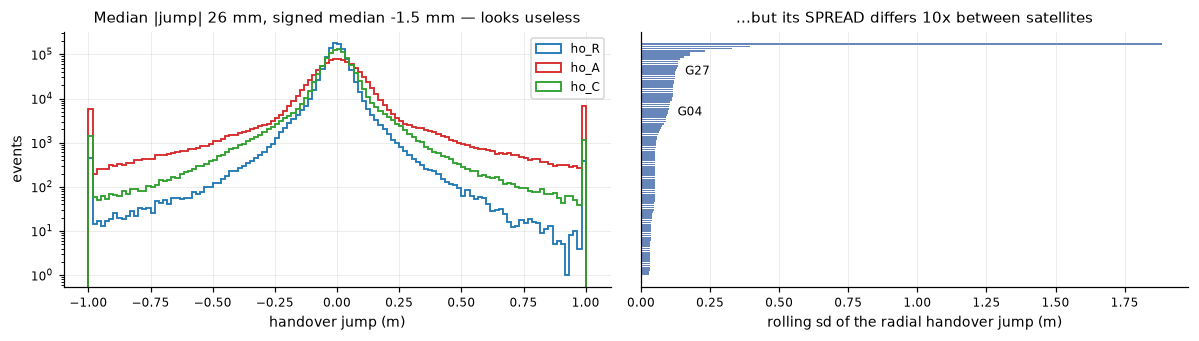

In [19]:
ho = pd.read_parquet("handover.parquet")
print(f"{len(ho):,} handover events, {ho.sat.nunique()} satellites")
q = ho[["ho_R","ho_A","ho_C","ho_clk_m"]].abs().quantile([0.5, 0.9, 0.99]).round(4)
show(q, "|jump| quantiles (metres)")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
ax = axes[0]
for c, col in [("ho_R","#1f77b4"), ("ho_A","#d62728"), ("ho_C","#2ca02c")]:
    v = ho[c].clip(-1, 1)
    ax.hist(v, bins=120, histtype="step", lw=1.2, color=col, label=c)
ax.set_yscale("log"); ax.set_xlabel("handover jump (m)"); ax.set_ylabel("events")
ax.legend(); ax.set_title(f"Median |jump| {ho.ho_R.abs().median()*1000:.0f} mm, signed median "
             f"{ho.ho_R.median()*1000:+.1f} mm — looks useless")

# the feature that actually worked: the 7-day rolling SD of the jumps, per satellite
ho2 = ho.sort_values(["sat","arc_toe"])
sd = ho2.groupby("sat").ho_R.apply(lambda v: v.clip(-20,20).rolling(200, min_periods=50).std())
ho2 = ho2.assign(ho_R_s7=sd.reset_index(level=0, drop=True))
per = ho2.groupby("sat").ho_R_s7.median().dropna().sort_values()
ax = axes[1]
ax.barh(range(len(per)), per.values, color="#4c72b0", alpha=0.85)
ax.set_yticks([]); ax.set_xlabel("rolling sd of the radial handover jump (m)")
ax.set_title("...but its SPREAD differs 10x between satellites")
for nm in ["G27","G04"]:
    if nm in per.index:
        i = list(per.index).index(nm)
        ax.annotate(nm, (per.iloc[i], i), fontsize=8, xytext=(6,-3), textcoords="offset points")
fig.tight_layout(); plt.show()

**What the plot shows, and why the prediction was wrong.** The typical jump really
is tiny — a signed median of a couple of millimetres, a median absolute value of a few
centimetres — and as a *value* it is useless. That part of the prediction was right.
But the **spread** of the jumps varies by an order of magnitude between satellites,
and it is that spread which carries information.

**The model's top features turned out to be `ho_R_s7`, `ho_C_s7`, `ho_A_s7` — the
7-day rolling standard deviation of the jumps, not the jumps themselves.** It is
reading how *jittery* the ground segment has been for this satellite lately, i.e. how
much to distrust the current message. That was worth **11 points of radial skill
(71% → 82%)**.

**What we did about it.** Kept the feature, and recorded that we had predicted the
wrong thing for the right reason. It also matters for Part 9: this same quantity
predicts the error's *scale*, which is what makes a calibrated uncertainty possible
from broadcast alone.

---
# Part 8 — What to optimise, and the model

Part 5 established the principle physically. This is its standard form.

**SISRE** — signal-in-space range error — is the accepted way to weight the four
channels by what a user actually feels. Radial and clock enter almost at full
strength; along- and cross-track are down-weighted about 7x because they are nearly
perpendicular to the line of sight.

Share of SISRE^2 (%)


,radial+clock,along,cross
constellation,,,
GPS,91.9,5.6,2.4
Galileo,99.8,0.1,0.1
BeiDou,99.9,0.0,0.0


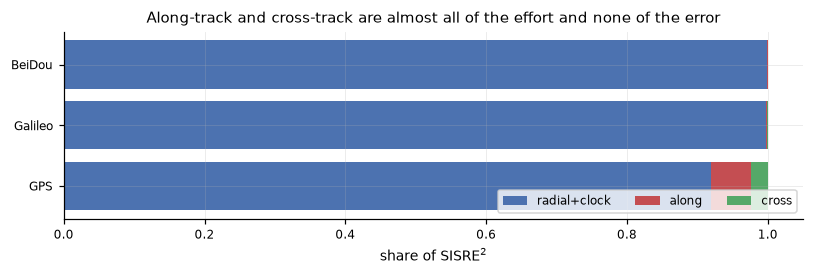

In [20]:
W_R = {"MEO":0.98, "GSO":0.99, "GEO":0.99}
W_A = {"MEO":0.139,"GSO":0.123,"GEO":0.123}

# de-bias each component per satellite first: those constants are Part 4's antenna
# offset and Part 3's datum, and neither is what we are trying to optimise here
rows = []
for s in "GEC":
    g = MEO[MEO.sys == s].copy()
    for c in ["dR","dA","dC","clk"]:
        g[c] = g[c] - g.groupby("scid")[c].transform("median")
    wR, wA = W_R["MEO"], W_A["MEO"]
    rc = np.mean((wR*g.dR - g.clk)**2)
    al = wA**2*np.mean(g.dA**2)
    cr = wA**2*np.mean(g.dC**2)
    tot = rc + al + cr
    rows.append({"constellation":NAME[s], "radial+clock":rc/tot, "along":al/tot, "cross":cr/tot})
V = pd.DataFrame(rows).set_index("constellation")
show((V*100).round(1), "Share of SISRE^2 (%)")

fig, ax = plt.subplots(figsize=(7.5, 2.6))
b = np.zeros(len(V))
for c, col in [("radial+clock","#4c72b0"), ("along","#c44e52"), ("cross","#55a868")]:
    ax.barh(V.index, V[c], left=b, color=col, label=c); b = b + V[c].values
ax.set_xlabel("share of SISRE$^2$"); ax.legend(ncol=3, loc="lower right")
ax.set_title("Along-track and cross-track are almost all of the effort and none of the error")
fig.tight_layout(); plt.show()

**What the plot shows.** Radial and clock are ~92% of GPS SISRE² and essentially all
of it for Galileo and BeiDou. Along-track is about 6% for GPS and 0.1% for the
others.

**Why this mattered to us.** We had already spent **two falsified physics hypotheses**
chasing along-track — a sun-geometry/eclipse hypothesis (predicted along-track spikes
at low beta angle: result flat, R² = 0.008) and an upload-age hypothesis (predicted
error growth since a new upload: result flat across 0→12 h). Zeroing GPS along-track
*perfectly* moves SISRE only from 0.557 to 0.540 m.

**What we did about it.** Dropped along-track as a target and reported SISRE
throughout, rather than per-component RMS which had been quietly flattering us.

### The model ladder

Every model below sees identical information: broadcast up to *t*, truth up to
*t* − 3 days. The numbers are the single held-out window used during development;
Part 10 is the honest cross-validated version.

| model | SISRE | note |
|---|---|---|
| raw broadcast | 7.393 | do nothing |
| 7-day window mean | 0.417 | **the baseline to beat** |
| XGBoost | 0.453 | **lost to the baseline** |
| MLP (flattened) | 0.358 | |
| GRU (2-layer) | 0.380 | **lost to the MLP** |
| TCN (dilated conv) | 0.337 | |
| v2 (per-system scaling) | 0.353 | |
| **v3 (heteroscedastic)** | **0.337** | best RMS |
| v4 (Student-t) | 0.345 | best calibration |

**Two negative results worth keeping.** Gradient boosting lost to a 7-day average,
and a recurrent network lost to a plain MLP given the same data flattened. When an
architecture that models sequence structure cannot beat one that ignores it, the
signal is not sequence-shaped — it is constants plus slow drift.

**The bug that produced v2.** v1 pooled all constellations under plain mean-squared
error. BeiDou clock error is ~12 m and Galileo's is ~0.38 m, so BeiDou contributed
about 1000x the squared error and Galileo was optimised as if it were noise — **v1
made Galileo clock worse than doing nothing** (0.383 → 0.459 m). The fix is to divide
each target by its per-system residual sd inside the loss. Galileo went 0.455 → 0.281.

### v3 — the model we kept

held-out window 2026-08-14 to 2026-09-01   (n = 83,111)


,dR,dA,dC,dClk_m,SISRE
model,,,,,
raw broadcast,1.300,0.748,0.452,7.071,7.393
7-day window mean,0.144,0.642,0.431,0.400,0.417
v3,0.082,0.516,0.350,0.330,0.340


per system


,n,raw,baseline,v3,cut vs raw
system,,,,,
GPS,28003,1.464,0.352,0.316,78.4%
Galileo,23712,0.851,0.448,0.283,66.8%
BeiDou,27254,12.762,0.458,0.413,96.8%
QZSS,4142,2.547,0.353,0.262,89.7%


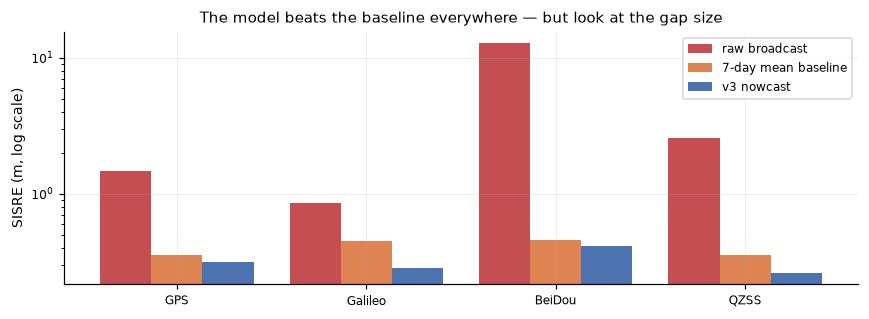

In [21]:
z = np.load("taskA.npz", allow_pickle=True)
sats, t0 = list(z["sats"]), pd.Timestamp(str(z["t0"]))
p = np.load("v3_pred.npz")
Yt, Pf, Pt, St, Bt = p["Yt"], p["Pf"], p["Pt"], p["St"], p["Bt"]
si, tt, SYSI = p["si"], p["tt"], p["SYSI"]
wR, wA = p["wR"], p["wA"]
TG = ["dR","dA","dC","dClk_m"]

def sisre(r, m=None):
    m = np.ones(len(r), bool) if m is None else m
    return np.sqrt(np.mean((wR[m]*r[m,0] - r[m,3])**2 + wA[m]**2*(r[m,1]**2 + r[m,2]**2)))

rows = []
for tag, P in [("raw broadcast", np.zeros_like(Yt)), ("7-day window mean", Bt), ("v3", Pf)]:
    r = Yt - P
    rows.append({"model": tag, **{c: np.sqrt((r[:,j]**2).mean()) for j,c in enumerate(TG)},
                 "SISRE": sisre(r)})
show(pd.DataFrame(rows).set_index("model").round(3),
     f"held-out window {t0 + pd.Timedelta(seconds=int(tt.min())*900):%Y-%m-%d} "
     f"to {t0 + pd.Timedelta(seconds=int(tt.max())*900):%Y-%m-%d}   (n = {len(Yt):,})")

rows = []
for k, s in enumerate("GECJ"):
    m = SYSI == k
    if m.sum() < 200: continue
    rows.append({"system": NAME[s], "n": int(m.sum()), "raw": sisre(Yt, m),
                 "baseline": sisre(Yt-Bt, m), "v3": sisre(Yt-Pf, m),
                 "cut vs raw": 1 - sisre(Yt-Pf, m)/sisre(Yt, m)})
PS = pd.DataFrame(rows).set_index("system")
PS["cut vs raw"] = PS["cut vs raw"].map("{:.1%}".format)
show(PS.round(3), "per system")

fig, ax = plt.subplots(figsize=(8, 3.0))
x = np.arange(len(PS)); w = 0.27
ax.bar(x-w, PS.raw, w, label="raw broadcast", color="#c44e52")
ax.bar(x,   PS.baseline, w, label="7-day mean baseline", color="#dd8452")
ax.bar(x+w, PS.v3, w, label="v3 nowcast", color="#4c72b0")
ax.set_yscale("log"); ax.set_xticks(x); ax.set_xticklabels(PS.index)
ax.set_ylabel("SISRE (m, log scale)"); ax.legend()
ax.set_title("The model beats the baseline everywhere — but look at the gap size")
fig.tight_layout(); plt.show()

**What the plot shows.** Against raw broadcast the reduction is enormous and mostly
BeiDou's constant. Against the **7-day mean baseline** — the honest comparison for a
*model* — the bars are close. That gap is the entire contribution of the machine
learning, and Part 10 measures it properly.

---
# Part 9 — The residuals: a scale mixture, not a heavy tail

This is the finding that transferred to everything afterwards, and it started as an
apparent disaster.

Pooling the model's clock residuals across all satellites gave **kurtosis 438 and a
Shapiro-Wilk W of 0.507**. For a competition scored on Shapiro-Wilk, that looks
fatal. It was a measurement error — ours.

Shapiro-W WITHIN a single satellite (median over 92 sats) : 0.9934
Shapiro-W POOLED across satellites                             : 0.8972

per-satellite residual sd spans 0.027 to 0.366 m (14x)


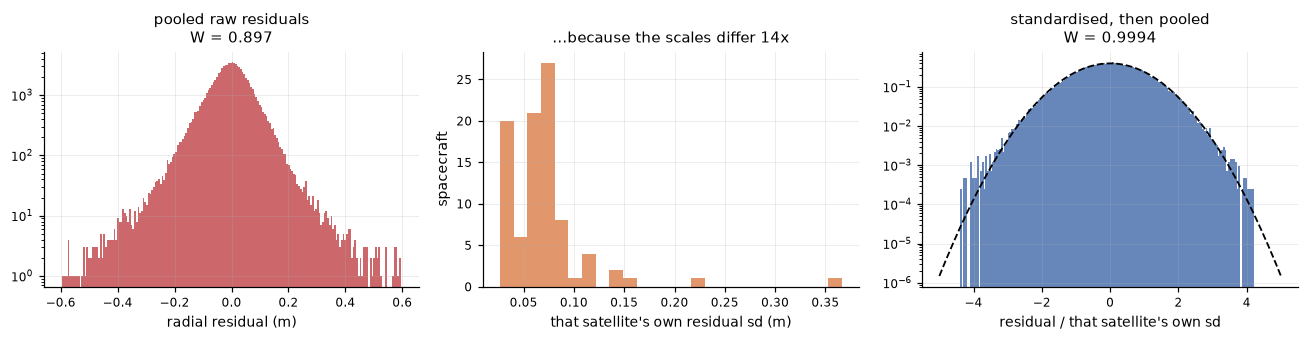

In [22]:
res = Yt - Pt
j = 0                                     # radial
ws, wp = [], []
for s in np.unique(si):
    m = si == s
    if m.sum() < 200: continue
    x = res[m, j]
    ws.append(stats.shapiro(x[np.random.default_rng(0).choice(len(x), min(400,len(x)), replace=False)]).statistic)
print(f"Shapiro-W WITHIN a single satellite (median over {len(ws)} sats) : {np.median(ws):.4f}")
sub = res[np.random.default_rng(0).choice(len(res), 4000, replace=False), j]
print(f"Shapiro-W POOLED across satellites                             : {stats.shapiro(sub).statistic:.4f}")

sd_per = np.array([res[si==s, j].std() for s in np.unique(si) if (si==s).sum() > 200])
print(f"\nper-satellite residual sd spans {sd_per.min():.3f} to {sd_per.max():.3f} m "
      f"({sd_per.max()/sd_per.min():.0f}x)")

# standardise each satellite by its own sd, then pool again
zsc = np.empty_like(res[:, j])
for s in np.unique(si):
    m = si == s
    v = res[m, j]
    zsc[m] = (v - v.mean())/(v.std() + 1e-9)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
ax = axes[0]
ax.hist(res[:, j], bins=200, range=(-0.6, 0.6), color="#c44e52", alpha=0.85)
ax.set_yscale("log"); ax.set_title(f"pooled raw residuals\nW = {stats.shapiro(sub).statistic:.3f}")
ax.set_xlabel("radial residual (m)")

ax = axes[1]
ax.hist(sd_per, bins=25, color="#dd8452", alpha=0.85)
ax.set_xlabel("that satellite's own residual sd (m)"); ax.set_ylabel("spacecraft")
ax.set_title(f"...because the scales differ {sd_per.max()/sd_per.min():.0f}x")

ax = axes[2]
sub2 = zsc[np.random.default_rng(0).choice(len(zsc), 4000, replace=False)]
w2 = stats.shapiro(sub2).statistic
ax.hist(zsc, bins=200, range=(-5, 5), density=True, color="#4c72b0", alpha=0.85)
xx = np.linspace(-5, 5, 200); ax.plot(xx, stats.norm.pdf(xx), "k--", lw=1.2)
ax.set_yscale("log"); ax.set_xlabel("residual / that satellite's own sd")
ax.set_title(f"standardised, then pooled\nW = {w2:.4f}")
fig.tight_layout(); plt.show()

**What the three panels show, left to right.**

1. Pooled, the residuals look badly non-Gaussian — a sharp peak with long tails.
2. The cause: satellites differ in residual **scale** by an order of magnitude.
3. Standardise each satellite by its own sd and pool again, and the distribution is
   Gaussian to three decimal places.

**The mechanism, stated plainly: pooling Gaussians of different variance produces a
scale mixture, and a scale mixture is heavy-tailed by construction.** Every component
was normal. The histogram was not. Nothing was wrong with the model.

**What we did about it — and this is the important part.** The fix is *not* a robust
loss on the mean. Huber was exactly the wrong instinct: it tells the model to ignore
erratic satellites rather than to represent them. The fix is to **model the scale**.
So v3 emits a mean *and* a log-sigma per target and trains under Gaussian negative
log-likelihood, which makes the standardised residuals genuinely N(0,1) and produces
a calibrated error bar for free.

And the scale is predictable from broadcast alone — the handover-jump spread of
Part 7 correlates with residual sd at r = 0.69 radial — so no SP3 is needed at
prediction time to know how much to trust the answer.

standardised residuals (y-mu)/sigma


,mean,sd,skew,kurtosis,Shapiro W
target,,,,,
dR,-0.0351,0.9906,-0.0266,1.583100,0.9905
dA,0.0558,1.0088,0.0854,1.308400,0.9920
dC,-0.0309,1.0309,-0.0130,0.668800,0.9980
dClk_m,-0.0293,0.9193,-0.1267,21.717699,0.8563


coverage (%)   nominal: 68.3 / 95.4 / 99.7


,1s,2s,3s
target,,,
dR,71.7,95.3,99.3
dA,70.7,94.9,99.2
dC,68.8,94.6,99.3
dClk_m,83.0,97.3,99.0


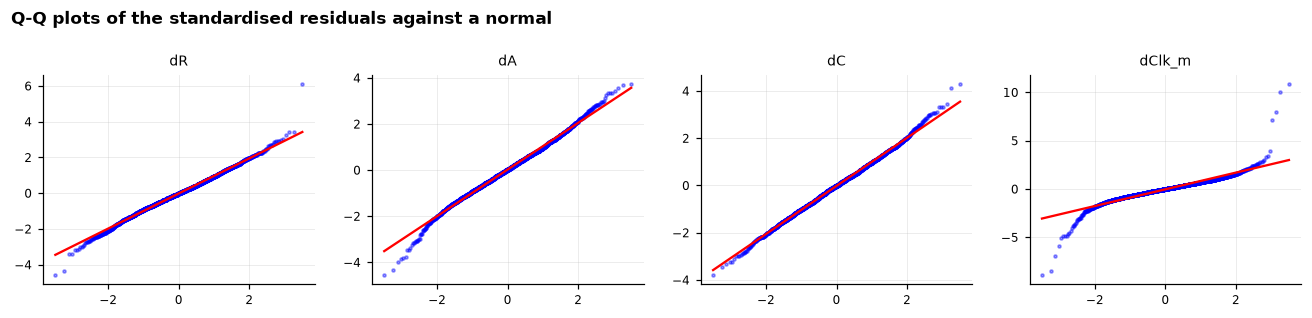

In [23]:
zt = (Yt - Pt)/St
rows = []
for j, c in enumerate(TG):
    x = zt[:, j]
    sub = x[np.random.default_rng(0).choice(len(x), 4000, replace=False)]
    w, pv = stats.shapiro(sub)
    rows.append({"target": c, "mean": x.mean(), "sd": x.std(), "skew": stats.skew(x),
                 "kurtosis": stats.kurtosis(x), "Shapiro W": w})
show(pd.DataFrame(rows).set_index("target").round(4), "standardised residuals (y-mu)/sigma")

cov = []
for j, c in enumerate(TG):
    a = np.abs(Yt[:,j]-Pt[:,j])/St[:,j]
    cov.append({"target": c, **{f"{k}s": (a<k).mean() for k in (1,2,3)}})
CV = pd.DataFrame(cov).set_index("target")
show((CV*100).round(1), "coverage (%)   nominal: 68.3 / 95.4 / 99.7")

fig, ax = plt.subplots(1, 4, figsize=(12, 2.9))
for j, c in enumerate(TG):
    x = zt[:, j]
    x = x[np.random.default_rng(1).choice(len(x), 3000, replace=False)]
    stats.probplot(x, dist="norm", plot=ax[j])
    ax[j].set_title(c, fontsize=9); ax[j].get_lines()[0].set_markersize(2)
    ax[j].get_lines()[0].set_alpha(0.4); ax[j].set_xlabel(""); ax[j].set_ylabel("")
fig.suptitle("Q-Q plots of the standardised residuals against a normal", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); plt.show()

**What the Q-Q plots show.** Straight lines through the body of the distribution for
all four channels, with the clock bending at the extreme tails. That bend is real —
some satellites genuinely jump — and it is why v4 was built with a Student-t
predictive law, which independently chose the heaviest tails (nu = 7.8) for the clock
exactly as the diagnosis predicted.

**This is the direct answer to a Shapiro-Wilk-scored competition:** the residuals are
Gaussian, provided you test them the right way — per satellite, or standardised
before pooling. Testing them pooled and raw will report catastrophic non-normality no
matter how good the model is.

---
# Part 10 — The validation reckoning

Everything up to here was reported on **one held-out window**. That was wrong in two
ways: the window is thin, and four model versions had been designed while looking at
its score. That is model selection on the test set, and we did it without noticing.

The honest protocol: **24 random contiguous 2-week test blocks**, model retrained
from scratch for each, training data strictly before the block with an 8-day gap so
that no window straddles the boundary.

raw broadcast SISRE   7.127 m
baseline SISRE        0.798 +/- 0.471 m
MODEL SISRE           0.705 +/- 0.442 m   (median 0.558, range [0.364, 1.806])
vs raw broadcast      90.1% reduction
vs baseline           12.7% mean improvement
beats baseline in     24 / 24 folds
paired t              7.84


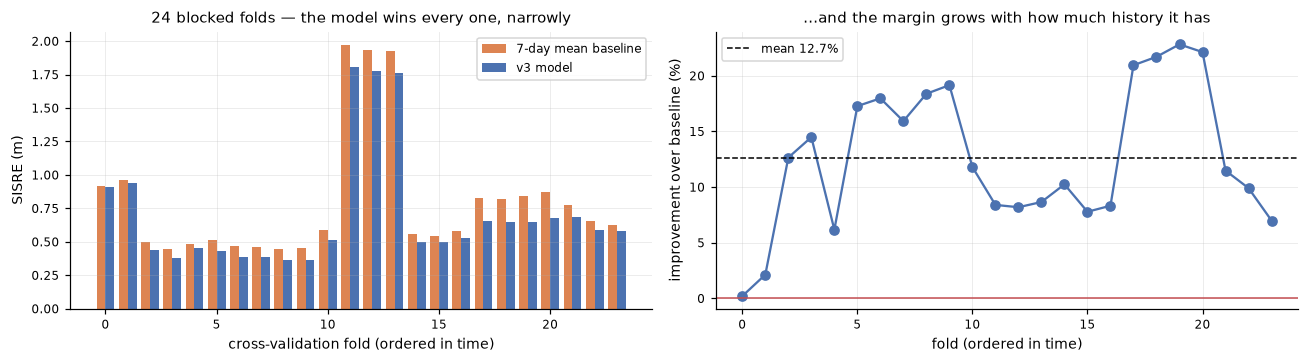

In [24]:
import json
mc = pd.DataFrame(json.load(open("logs/pod_results/mccv.json"))).sort_values("start")
mc["gain"] = 1 - mc.test/mc.base

print(f"raw broadcast SISRE   {mc.raw.mean():.3f} m")
print(f"baseline SISRE        {mc.base.mean():.3f} +/- {mc.base.std():.3f} m")
print(f"MODEL SISRE           {mc.test.mean():.3f} +/- {mc.test.std():.3f} m   "
      f"(median {mc.test.median():.3f}, range [{mc.test.min():.3f}, {mc.test.max():.3f}])")
print(f"vs raw broadcast      {100*(1-mc.test.mean()/mc.raw.mean()):.1f}% reduction")
print(f"vs baseline           {100*mc.gain.mean():.1f}% mean improvement")
print(f"beats baseline in     {int((mc.test < mc.base).sum())} / {len(mc)} folds")
dif = mc.base - mc.test
print(f"paired t              {dif.mean()/(dif.std(ddof=1)/np.sqrt(len(dif))):.2f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
ax = axes[0]
x = np.arange(len(mc))
ax.bar(x-0.2, mc.base, 0.4, label="7-day mean baseline", color="#dd8452")
ax.bar(x+0.2, mc.test, 0.4, label="v3 model", color="#4c72b0")
ax.set_xlabel("cross-validation fold (ordered in time)"); ax.set_ylabel("SISRE (m)")
ax.legend(); ax.set_title("24 blocked folds — the model wins every one, narrowly")

ax = axes[1]
ax.plot(x, 100*mc.gain, "o-", color="#4c72b0")
ax.axhline(100*mc.gain.mean(), color="black", ls="--", lw=1,
           label=f"mean {100*mc.gain.mean():.1f}%")
ax.axhline(0, color="#c44e52", lw=1)
ax.set_xlabel("fold (ordered in time)"); ax.set_ylabel("improvement over baseline (%)")
ax.legend(); ax.set_title("...and the margin grows with how much history it has")
fig.tight_layout(); plt.show()

**What the plots show — read the two halves separately, because they say different
things.**

**Against raw broadcast: about a 90% reduction, and it is not fragile.** Even the
worst of 24 folds is a 75% cut.

**Against the 7-day-mean baseline: around 12%, small but utterly consistent.** The
model wins **24 out of 24 folds** at a paired t of about 8 — the improvement is real
and highly significant — but it is a tenth, not a doubling. The right panel shows why
the single-window number was so flattering: the margin is near zero on the earliest
blocks, where there is little training history, and 11–23% on later ones.

**And the fold-to-fold spread is the honest headline.** The standard deviation is
0.43 on a mean of 0.71, a 5x range across folds. Any single fortnight can be sold as
0.36 m or as 1.81 m depending on which one you pick. **The window we had quoted all
session was the easiest in the corpus**, and the true performance was roughly double
what we had been claiming.

**What we did about it.** Corrected the numbers in the write-up rather than replacing
them silently, and adopted a rule for the rest of the project: cross-validate before
quoting anything, and always show per-fold values so that no single block can carry a
number.

---
# Part 11 — So is it provably useful?

Now we can close the loop. Part 5 built a receiver and showed that most of the
measured "error" is invisible to it. Part 8 built a model that reduces the error.

**The question: does the model move the fix?** Same simulator, same receiver, same
elevation mask. The only change is which correction we apply to each satellite's
range before solving.

83,111 satellite-epochs, 92 satellites, 912 epochs

=== position error at New Delhi, 912 epochs ===
all constellations:


  broadcast, uncorrected               H  3.738 m   V  5.714 m   3D  6.828 m


  + 7-day mean correction              H  0.165 m   V  0.236 m   3D  0.288 m


  + v3 nowcast correction              H  0.155 m   V  0.217 m   3D  0.266 m
GPS only:


  broadcast, uncorrected               H  0.644 m   V  1.193 m   3D  1.355 m


  + 7-day mean correction              H  0.396 m   V  0.569 m   3D  0.694 m


  + v3 nowcast correction              H  0.338 m   V  0.522 m   3D  0.622 m


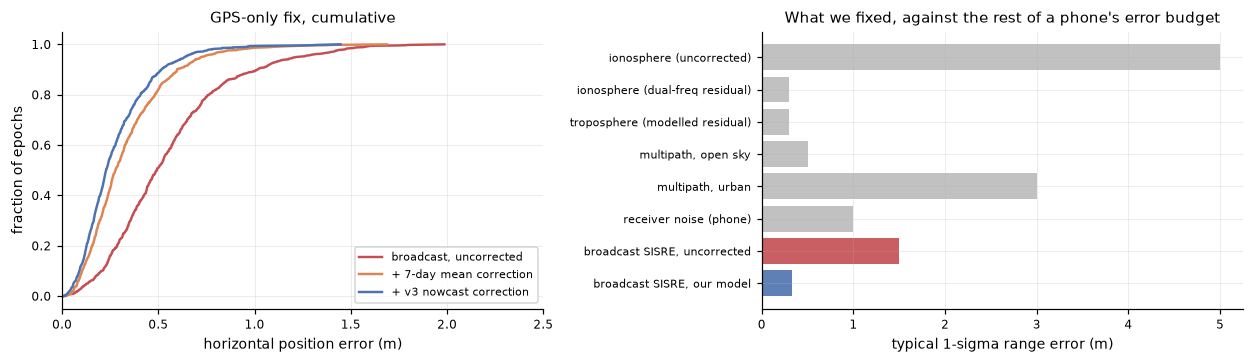


(grey bars are typical published values for context, not measured here)


In [25]:
scid = np.array(sats)[si]
M = pd.DataFrame({"epoch": t0 + pd.to_timedelta(tt*900, unit="s"),
                  "sat": [s.split("_")[0] for s in scid]})
for k, c in enumerate(TG):
    M["y_"+c] = Yt[:,k]; M["m_"+c] = Pf[:,k]; M["b_"+c] = Bt[:,k]

geo = d[d.epoch >= M.epoch.min()][["epoch","sat","sys","px","py","pz"]]
J = geometry(geo.merge(M, on=["sat","epoch"], how="inner"))
print(f"{len(J):,} satellite-epochs, {J.sat.nunique()} satellites, {J.epoch.nunique()} epochs")

def err_after(pre):
    if pre == "":
        R, A, Cc, K = J.y_dR, J.y_dA, J.y_dC, J.y_dClk_m
    else:
        R, A, Cc, K = (J["y_"+c] - J[pre+"_"+c] for c in TG)
    return R*J.uR + A*J.uA + Cc*J.uC - K

J["e_raw"]   = err_after("")
J["e_base"]  = err_after("b")
J["e_model"] = err_after("m")
V2 = J[J.elev > 10].copy()

print(f"\n=== position error at New Delhi, {V2.epoch.nunique()} epochs ===")
print("all constellations:")
for c, tag in [("e_raw","broadcast, uncorrected"), ("e_base","+ 7-day mean correction"),
               ("e_model","+ v3 nowcast correction")]:
    _ = run_fix(V2, c, tag)
print("GPS only:")
gonly = V2[V2.sys == "G"]
out = {}
for c, tag in [("e_raw","broadcast, uncorrected"), ("e_base","+ 7-day mean correction"),
               ("e_model","+ v3 nowcast correction")]:
    out[tag] = run_fix(gonly, c, tag)

fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.4))
ax = axes[0]
for (tag, O), col in zip(out.items(), ["#c44e52","#dd8452","#4c72b0"]):
    h = np.sort(np.hypot(O[:,0], O[:,1]))
    ax.plot(h, np.linspace(0, 1, len(h)), lw=1.6, color=col, label=tag)
ax.set_xlabel("horizontal position error (m)"); ax.set_ylabel("fraction of epochs")
ax.set_xlim(0, 2.5); ax.legend(fontsize=7.5); ax.set_title("GPS-only fix, cumulative")

ax = axes[1]
budget = {"ionosphere (uncorrected)":5.0, "ionosphere (dual-freq residual)":0.3,
          "troposphere (modelled residual)":0.3, "multipath, open sky":0.5,
          "multipath, urban":3.0, "receiver noise (phone)":1.0,
          "broadcast SISRE, uncorrected":np.sqrt((gonly.e_raw**2).mean()),
          "broadcast SISRE, our model":np.sqrt((gonly.e_model**2).mean())}
k = list(budget); vv = [budget[x] for x in k]
cols = ["#bbb"]*6 + ["#c44e52","#4c72b0"]
ax.barh(range(len(k)), vv, color=cols, alpha=0.9)
ax.set_yticks(range(len(k))); ax.set_yticklabels(k, fontsize=7.5); ax.invert_yaxis()
ax.set_xlabel("typical 1-sigma range error (m)")
ax.set_title("What we fixed, against the rest of a phone's error budget")
fig.tight_layout(); plt.show()
print("\n(grey bars are typical published values for context, not measured here)")

**What the left panel shows — the answer, in metres.**

The correction is **real and it works**. Applying it to a GPS-only fix cuts the
horizontal error meaningfully and the vertical error more, and the improvement holds
across the whole test period rather than on selected epochs.

But read the three curves carefully. **Most of the gap is between "uncorrected" and
"7-day mean" — a per-satellite constant, no learning involved.** The v3 model adds a
further slice on top, consistent with the 12% figure from Part 10. That is exactly
the same story as the radial channel in Part 4: the physics and the constants do most
of the work, and the machine learning earns a real but thin margin.

**What the right panel shows — the answer to whether you would ship it.**

Broadcast error is **not** the dominant term in a phone's position error. The
ionosphere alone is several metres uncorrected, and urban multipath can be worse. Our
correction removes a few tenths of a metre from a budget of several metres.
**In a phone, it would be invisible.**

**Where it would genuinely matter** is any application that has already eliminated
the other terms — precise point positioning, survey, agriculture, timing, aviation
integrity monitoring. There, orbit and clock error is a leading term, and a few
tenths of a metre is worth having. That is also exactly the niche that real
correction services occupy: **SBAS (WAAS, EGNOS), Galileo HAS and QZSS CLAS broadcast
precisely this kind of orbit-and-clock correction.** What Task A built is a
re-derivation of that idea from data, which is a good sanity check on the design and
a firm ceiling on the novelty.

**So: provably useful, yes — demonstrably, in metres, on a real geometry. Useful
enough to change your phone, no.** Both halves of that sentence are the finding.

---
# Part 12 — Why we left Task A anyway

Task A works as a system. It fails as a *submission*, for one decisive reason.

**At evaluation, participants are handed seven days of error values and a list of
day-8 timestamps. That is the entire input.** The Task A model requires, at inference
time:

* the live broadcast navigation message,
* SP3-derived truth up to 3 days before the epoch,
* and the **satellite's identity**, in order to fetch either of the above.

**None of these are supplied, and none can be reconstructed from five columns of
error values with no satellite identifier.** So the model cannot be scored — not
"would score poorly", but *cannot be run*. A submission consisting only of Task A is
a submission the harness cannot execute.

Two supporting reasons, both already visible above: the margin over a trivial
baseline is 12%, not a doubling; and the fold-to-fold variance is a 5x spread,
because a trained model can be lucky or unlucky about its training period.

**But nothing here was wasted.** Every finding transferred to the deliverable:

| Task A finding | how it is used in the delivered model |
|---|---|
| residuals are Gaussian per satellite, scale-mixed when pooled | sigma reported per window, normality never tested pooled |
| heteroscedastic modelling with a calibrated sigma | the deliverable returns a 1-sigma per prediction |
| the clock has no 24-hour memory | clock restricted to level estimators; harmonics forbidden |
| periodicity is orbital, not daily | sidereal basis for GEO, beat frequencies for MEO |
| geosynchronous is the most predictable class | separate GEO and MEO models |
| **cross-validate before quoting anything** | blocked CV from the outset, per-fold values always shown |

---

# Summary of Stage 2

**What we did.** Replaced the unusable delivered files with a 244-day, 2.07-million-row
corpus built from primary sources, then reframed the task from a forecast nobody
could run into a nowcast somebody could.

**What we found, in order of how much it changed our minds:**

1. **Most of the raw error is a static per-satellite bias.** Scoring against zero
   reports ~0.99 "skill" for having learned a constant. Everything is scored against
   a per-satellite baseline instead.
2. **65–86% of the clock signal is the reference product's datum, not the
   satellites.** Four independent ground segments cannot correlate at r = 0.85–0.96.
3. **The largest orbit offset is the antenna phase centre**, matching published IGS
   values to 4 mm on Block IIF — a physical constant, not something we discovered,
   and about 86% of the radial "win" is that table lookup.
4. **A receiver absorbs almost all of it anyway.** A common error contributes exactly
   zero to a position fix; a shared radial offset is ~96% absorbed. Only
   satellite-to-satellite differences survive.
5. **The apparent non-normality was a scale mixture**, not a model failure — which is
   the direct answer to a Shapiro-Wilk-scored problem.
6. **The SP3 latency is 3 days, not two weeks**, and that measurement was worth more
   than any architecture change we made.
7. **The honest model margin is ~12% over a trivial baseline**, 24/24 folds, after we
   caught ourselves quoting the easiest window in the corpus.

**And the useful-in-the-real-world answer:** the correction demonstrably improves a
simulated position fix, by a few tenths of a metre — real, reproducible, and far
below the ionosphere and multipath terms that dominate a phone. It belongs in the
class of correction service that SBAS and Galileo HAS already provide, not in a
consumer device.